# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`ransformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді:
1. ...

---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

In [1]:
!pip install -q "transformers<5" datasets tensorboard psutil

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 106.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 44.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 104.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os
import gc
import math
import time
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    LAB_DIR = "/content/drive/MyDrive/ai_systems/Лаба 3"
except ImportError:
    LAB_DIR = "Лаба 3"

MODELS_DIR = os.path.join(LAB_DIR, "models")
RUNS_DIR = os.path.join(LAB_DIR, "runs")
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", LAB_DIR)

Використовуємо: cuda
Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/Лаба 3


In [3]:
from datasets import load_dataset

NUM_DOCS = 300_000

ukr_dataset = load_dataset("ukr-models/Ukr-Synth", split="train", revision="refs/convert/parquet")
print("Усього речень у датасеті:", len(ukr_dataset))
print("Колонки:", ukr_dataset.column_names)

ukr_dataset = ukr_dataset.select_columns(["text"]).select(range(NUM_DOCS))
texts = list(ukr_dataset["text"])
print("Взято речень:", len(texts))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Ukr-Synth/train/0000.parquet:   0%|          | 0.00/60.1M [00:00<?, ?B/s]

Ukr-Synth/train/0001.parquet:   0%|          | 0.00/60.2M [00:00<?, ?B/s]

Ukr-Synth/train/0002.parquet:   0%|          | 0.00/60.1M [00:00<?, ?B/s]

Ukr-Synth/train/0003.parquet:   0%|          | 0.00/60.2M [00:00<?, ?B/s]

...

Ukr-Synth/train/0005.parquet:   0%|          | 0.00/27.9M [00:00<?, ?B/s]

Ukr-Synth/validation/0000.parquet:   0%|          | 0.00/3.32M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Усього речень у датасеті: 1000000
Колонки: ['idx', 'text', 'tokens', 'lemmas', 'upos', 'xpos', 'feats', 'head', 'deprel', 'deps', 'misc']
Взято речень: 300000


In [4]:
corpus_text = "\n".join(texts)
word_counts = Counter(w.lower() for t in texts for w in t.split())
sentence_lengths = pd.Series([len(t) for t in texts])

print("Розмір корпусу:", len(corpus_text), "символів")
print("Слів (з повторами):   ", sum(word_counts.values()))
print("Унікальних слів:      ", len(word_counts))
print(sentence_lengths.describe().round(1))
print("Перші 500 символів корпусу:\n")
print(corpus_text[:500])

Розмір корпусу: 30946067 символів
Слів (з повторами):    4375459
Унікальних слів:       429966
count    300000.0
mean        102.2
std          46.7
min          40.0
25%          66.0
50%          91.0
75%         128.0
max         255.0
dtype: float64
Перші 500 символів корпусу:

Чим довше мають скачки тиску гіпертензією, тим сильніше змінюються стінки цих судин.
А поки що починали цвісти троянди, випускники складали іспити, учні відпочивали в пришкільному таборі, а директор Володимир Хоботов марно оббивав пороги в пошуках транспорту.
Крім того, в 2020 р. багато експертів прогнозують виникнення кризових явищ на світових фінансових ринках, що може ускладнити залучення зовнішніх позик.
Сильно сумніваюся, що ви зупините свій вибір на такому цілителі.
Цей унікальний правовий


---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

In [5]:
!pip install -q "transformers<5"

In [6]:
from transformers import AutoTokenizer

WARMUP_VOCAB = 2000
WARMUP_DOCS = 50_000

base_tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")

def text_batches(batch_size=1000):
    for start in range(0, WARMUP_DOCS, batch_size):
        yield texts[start:start + batch_size]

warmup_tokenizer = base_tokenizer.train_new_from_iterator(text_batches(), vocab_size=WARMUP_VOCAB)

probe = "Президент України підписав закон про електронне декларування."
print("Qwen2.5:", len(base_tokenizer.tokenize(probe)), "токенів")
print(f"Новий (vocab={WARMUP_VOCAB}):", len(warmup_tokenizer.tokenize(probe)), "токенів")
print(warmup_tokenizer.tokenize(probe))

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Qwen2.5: 24 токенів
Новий (vocab=2000): 16 токенів
['ÐŁÑĢ', 'ÐµÐ·Ð¸Ð´ÐµÐ½ÑĤ', 'ĠÐ£ÐºÑĢÐ°ÑĹÐ½Ð¸', 'ĠÐ¿ÑĸÐ´Ð¿Ð¸Ñģ', 'Ð°Ð²', 'ĠÐ·Ð°ÐºÐ¾Ð½', 'ĠÐ¿ÑĢÐ¾', 'ĠÐµÐ»ÐµÐº', 'ÑĤÑĢ', 'Ð¾Ð½', 'Ð½Ðµ', 'ĠÐ´ÐµÐº', 'Ð»', 'Ð°ÑĢ', 'ÑĥÐ²Ð°Ð½Ð½Ñı', '.']


##  BPE, WordPiece, Unigram на власному тексті

In [7]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, normalizers

CMP_VOCAB = 500
sample_texts = texts[:5000]

bpe_cmp = Tokenizer(models.BPE(unk_token="<unk>"))
bpe_cmp.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
bpe_cmp.decoder = decoders.ByteLevel()
bpe_cmp.train_from_iterator(
    sample_texts,
    trainers.BpeTrainer(
        vocab_size=CMP_VOCAB,
        special_tokens=["<unk>", "<eos>"],
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
    ),
)

wp_cmp = Tokenizer(models.WordPiece(unk_token="[UNK]"))
wp_cmp.normalizer = normalizers.BertNormalizer(
    clean_text=True, handle_chinese_chars=True, strip_accents=False, lowercase=False
)
wp_cmp.pre_tokenizer = pre_tokenizers.BertPreTokenizer()
wp_cmp.decoder = decoders.WordPiece(prefix="##")
wp_cmp.train_from_iterator(
    sample_texts,
    trainers.WordPieceTrainer(
        vocab_size=CMP_VOCAB,
        special_tokens=["[UNK]", "[CLS]", "[SEP]", "[PAD]", "[MASK]"],
    ),
)

uni_cmp = Tokenizer(models.Unigram())
uni_cmp.normalizer = normalizers.NFKC()
uni_cmp.pre_tokenizer = pre_tokenizers.Metaspace()
uni_cmp.decoder = decoders.Metaspace()
uni_cmp.train_from_iterator(
    sample_texts,
    trainers.UnigramTrainer(
        vocab_size=CMP_VOCAB,
        special_tokens=["<unk>", "<eos>"],
        unk_token="<unk>",
    ),
)

comparison = {"BPE": bpe_cmp, "WordPiece": wp_cmp, "Unigram": uni_cmp}
for name, tok in comparison.items():
    print(f"{name:<10} розмір словника: {tok.get_vocab_size()}")

BPE        розмір словника: 500
WordPiece  розмір словника: 500
Unigram    розмір словника: 500


In [8]:
sample_counts = Counter(w for t in sample_texts for w in t.split())
frequent_word = next(w for w, c in sample_counts.most_common() if w.isalpha() and len(w) >= 5)
rare_word = next((w for w, c in sample_counts.items() if c == 1 and w.isalpha() and len(w) >= 12), "електроенергії")
probe_words = list(dict.fromkeys([frequent_word, "Україна", rare_word]))

rows = []
for name, tok in comparison.items():
    encodings = tok.encode_batch(sample_texts)
    total_tokens = sum(len(e.ids) for e in encodings)
    row = {
        "Алгоритм": name,
        "Розмір словника": tok.get_vocab_size(),
        "Токенів на зразку": total_tokens,
        "Токенів на речення": round(total_tokens / len(sample_texts), 2),
    }
    for word in probe_words:
        row[f"токенів у «{word}»"] = len(tok.encode(word).ids)
    rows.append(row)

tokenizer_table = pd.DataFrame(rows)
display(tokenizer_table)

for word in probe_words:
    print(f"\n«{word}»")
    for name, tok in comparison.items():
        print(f"  {name:<10}", tok.encode(word).tokens)

,Алгоритм,Розмір словника,Токенів на зразку,Токенів на речення,токенів у «також»,токенів у «Україна»,токенів у «пришкільному»
0,BPE,500,303610,60.72,3,3,7
1,WordPiece,500,277977,55.60,3,2,6
2,Unigram,500,271754,54.35,1,2,7



«також»
  BPE        ['ÑĤ', 'Ð°Ðº', 'Ð¾Ð¶']
  WordPiece  ['та', '##ко', '##ж']
  Unigram    ['▁також']

«Україна»
  BPE        ['Ð£', 'ÐºÑĢÐ°ÑĹ', 'Ð½Ð°']
  WordPiece  ['Украї', '##на']
  Unigram    ['▁Україн', 'а']

«пришкільному»
  BPE        ['Ð¿', 'ÑĢÐ¸', 'ÑĪ', 'Ðº', 'ÑĸÐ»ÑĮ', 'Ð½', 'Ð¾Ð¼Ñĥ']
  WordPiece  ['при', '##ш', '##к', '##іль', '##но', '##му']
  Unigram    ['▁при', 'ш', 'к', 'і', 'ль', 'н', 'ому']


In [9]:
shortest = tokenizer_table.loc[tokenizer_table["Токенів на зразку"].idxmin()]
longest = tokenizer_table.loc[tokenizer_table["Токенів на зразку"].idxmax()]
print(
    f"Найкоротші послідовності на зразку дав {shortest['Алгоритм']}: "
    f"{shortest['Токенів на речення']} токенів/речення проти "
    f"{longest['Токенів на речення']} у {longest['Алгоритм']}."
)

Найкоротші послідовності на зразку дав Unigram: 54.35 токенів/речення проти 60.72 у BPE.


## Підсумки порівняння:

- **BPE** (ByteLevel) стартує з 256 байтів і жадібно зливає найчастіші пари. Кирилиця займає по 2 байти на літеру, тому на малому словнику частину бюджету з'їдає відновлення самих літер.
- **WordPiece** стартує з символів (початкових та з префіксом `##`) і обирає пару за оцінкою `freq(пара) / (freq(a) * freq(b))`, тобто віддає перевагу парам, частини яких рідко трапляються окремо. Невідоме слово розбивається на підслова або дає `[UNK]`.
- **Unigram** починає з великого словника і поступово викидає токени, видалення яких найменше збільшує втрати. Це ймовірнісна модель, яка вибирає найімовірніше розбиття слова.

Який алгоритм дав найкоротші послідовності саме на цьому зразку, показано в таблиці та виводі вище.

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

## 3.1. Корпус і токенізація

In [10]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

SPECIAL_TOKENS = ["<unk>", "<eos>"]
ENCODE_BATCH_SIZE = 5000

def train_bpe(vocab_size):
    tok = Tokenizer(models.BPE(unk_token="<unk>"))
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size,
        special_tokens=SPECIAL_TOKENS,
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
    )
    tok.train_from_iterator(texts, trainer=trainer, length=len(texts))
    return tok

def encode_corpus(tok):
    eos_id = tok.token_to_id("<eos>")
    chunks = []
    for start in range(0, len(texts), ENCODE_BATCH_SIZE):
        for enc in tok.encode_batch(texts[start:start + ENCODE_BATCH_SIZE]):
            chunks.append(np.array(enc.ids + [eos_id], dtype=np.int32))
    token_ids = np.concatenate(chunks)
    del chunks
    gc.collect()
    return token_ids

## 3.2. Варіанти моделі

In [11]:
VARIANTS = [
    {"name": "minigpt_v1", "desc": "baseline", "vocab_size": 8000, "context_len": 64, "n_layers": 4, "n_heads": 4, "max_iters": 4000},
    {"name": "minigpt_v2", "desc": "vocab_4000", "vocab_size": 4000, "context_len": 64, "n_layers": 4, "n_heads": 4, "max_iters": 4000},
    {"name": "minigpt_v3", "desc": "layers_6", "vocab_size": 8000, "context_len": 64, "n_layers": 6, "n_heads": 4, "max_iters": 4000},
    {"name": "minigpt_v4", "desc": "context_128", "vocab_size": 8000, "context_len": 128, "n_layers": 4, "n_heads": 4, "max_iters": 4000},
]

EMBED_DIM = 128
DROPOUT = 0.1
BATCH_SIZE = 64
LEARNING_RATE = 3e-4
EVAL_INTERVAL = 250
EVAL_ITERS = 50

corpora = {}
for vocab_size in sorted({v["vocab_size"] for v in VARIANTS}):
    tok = train_bpe(vocab_size)
    token_ids = encode_corpus(tok)
    unk_share = float((token_ids == tok.token_to_id("<unk>")).mean())
    data = torch.from_numpy(token_ids.astype(np.int64))
    split_idx = int(len(data) * 0.9)
    corpora[vocab_size] = {
        "tokenizer": tok,
        "train": data[:split_idx],
        "val": data[split_idx:],
        "chars_per_token": len(corpus_text) / len(data),
    }
    print(
        f"VOCAB={vocab_size}: токенів {len(data):,}  <unk> {unk_share:.4%}  "
        f"символів/токен {corpora[vocab_size]['chars_per_token']:.2f}  "
        f"train {len(data[:split_idx]):,}  val {len(data[split_idx:]):,}"
    )
    del token_ids, data
    gc.collect()

VOCAB=4000: токенів 10,025,731  <unk> 0.0000%  символів/токен 3.09  train 9,023,157  val 1,002,574
VOCAB=8000: токенів 8,640,754  <unk> 0.0000%  символів/токен 3.58  train 7,776,678  val 864,076


In [12]:
class AttentionHead(nn.Module):
    def __init__(self, embed_dim, head_dim, context_len, dropout):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("causal_mask", torch.tril(torch.ones(context_len, context_len)))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.query(x), self.key(x), self.value(x)
        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = self.dropout(F.softmax(scores, dim=-1))
        return weights @ v


class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList(
            [AttentionHead(embed_dim, head_dim, context_len, dropout) for _ in range(n_heads)]
        )
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, embed_dim, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.GELU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(self, vocab_size, embed_dim, n_heads, n_layers, context_len, dropout):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(
            *[TransformerBlock(embed_dim, n_heads, context_len, dropout) for _ in range(n_layers)]
        )
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.token_embedding(idx) + self.position_embedding(torch.arange(T, device=idx.device))
        x = self.final_norm(self.blocks(x))
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        self.eval()
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -self.context_len:])
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                values, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits = logits.masked_fill(logits < values[:, [-1]], float("-inf"))
            probs = F.softmax(logits, dim=-1)
            idx = torch.cat([idx, torch.multinomial(probs, num_samples=1)], dim=1)
        return idx


def build_model(cfg):
    assert EMBED_DIM % cfg["n_heads"] == 0
    return MiniGPT(
        vocab_size=corpora[cfg["vocab_size"]]["tokenizer"].get_vocab_size(),
        embed_dim=EMBED_DIM,
        n_heads=cfg["n_heads"],
        n_layers=cfg["n_layers"],
        context_len=cfg["context_len"],
        dropout=DROPOUT,
    ).to(device)

In [13]:
from torch.utils.tensorboard import SummaryWriter

def make_batch_fn(train_data, val_data, context_len, batch_size):
    offsets = torch.arange(context_len)

    def get_batch(split):
        source = train_data if split == "train" else val_data
        ix = torch.randint(len(source) - context_len - 1, (batch_size,))
        idx = ix[:, None] + offsets[None, :]
        return source[idx].to(device), source[idx + 1].to(device)

    return get_batch


@torch.no_grad()
def estimate_loss(model, get_batch):
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(EVAL_ITERS)
        for i in range(EVAL_ITERS):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[i] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


def release_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def train_variant(cfg):
    corpus = corpora[cfg["vocab_size"]]
    get_batch = make_batch_fn(corpus["train"], corpus["val"], cfg["context_len"], BATCH_SIZE)
    model = build_model(cfg)
    n_params = sum(p.numel() for p in model.parameters())
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

    log_dir = os.path.join(RUNS_DIR, f'{cfg["name"]}_{cfg["desc"]}')
    writer = SummaryWriter(log_dir=log_dir)
    writer.add_text("config", str(cfg))

    history = {"iters": [], "train": [], "val": []}
    best_val, best_iter, best_state = float("inf"), None, None
    start_time = time.time()

    for it in range(cfg["max_iters"]):
        xb, yb = get_batch("train")
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        if it % EVAL_INTERVAL == 0 or it == cfg["max_iters"] - 1:
            losses = estimate_loss(model, get_batch)
            history["iters"].append(it)
            history["train"].append(losses["train"])
            history["val"].append(losses["val"])
            writer.add_scalar("Loss/train", losses["train"], it)
            writer.add_scalar("Loss/val", losses["val"], it)
            if losses["val"] < best_val:
                best_val, best_iter = losses["val"], it
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            elapsed = (time.time() - start_time) / 60
            print(
                f"{cfg['name']}  iter {it:5d}  train_loss={losses['train']:.3f}  "
                f"val_loss={losses['val']:.3f}  ({elapsed:.1f} хв)"
            )

    writer.close()
    torch.save(best_state, os.path.join(MODELS_DIR, f'{cfg["name"]}.pt'))

    result = {
        "experiment": "mini-GPT",
        "model": cfg["name"],
        "variant": cfg["desc"],
        "vocab_size": cfg["vocab_size"],
        "context_len": cfg["context_len"],
        "n_layers": cfg["n_layers"],
        "n_heads": cfg["n_heads"],
        "max_iters": cfg["max_iters"],
        "params": n_params,
        "best_iter": best_iter,
        "val_loss": best_val,
        "val_loss_per_char": best_val / corpus["chars_per_token"],
        "train_minutes": (time.time() - start_time) / 60,
    }

    del model, optimizer, best_state, writer, get_batch
    release_gpu()
    return result, history

In [14]:
_check_corpus = corpora[VARIANTS[0]["vocab_size"]]
_check_ctx = VARIANTS[0]["context_len"]
_check_batch = make_batch_fn(_check_corpus["train"], _check_corpus["val"], _check_ctx, BATCH_SIZE)

for split in ("train", "val"):
    xb, yb = _check_batch(split)
    assert xb.shape == yb.shape == (BATCH_SIZE, _check_ctx), f"неправильна форма батча: {xb.shape}, {yb.shape}"
    assert xb.dtype == torch.long and yb.dtype == torch.long
    assert torch.equal(yb[:, :-1], xb[:, 1:]), "yb не є xb, зсунутим на 1 токен"
    vocab_n = _check_corpus["tokenizer"].get_vocab_size()
    assert int(xb.max()) < vocab_n and int(yb.max()) < vocab_n and int(xb.min()) >= 0
print("assert-тести get_batch пройдено")
del _check_corpus, _check_ctx, _check_batch, xb, yb, vocab_n

assert-тести get_batch пройдено


In [15]:
results_rows = []
histories = {}

for cfg in VARIANTS:
    print(f"\n=== {cfg['name']} ({cfg['desc']}) ===")
    result, history = train_variant(cfg)
    results_rows.append(result)
    histories[cfg["name"]] = history

mini_gpt_df = pd.DataFrame(results_rows)
display(mini_gpt_df)
pd.DataFrame(results_rows).to_csv(os.path.join(LAB_DIR, "results.csv"), index=False)


=== minigpt_v1 (baseline) ===
minigpt_v1  iter     0  train_loss=9.139  val_loss=9.140  (0.0 хв)
minigpt_v1  iter   250  train_loss=7.235  val_loss=7.222  (0.2 хв)
minigpt_v1  iter   500  train_loss=6.964  val_loss=6.972  (0.3 хв)
minigpt_v1  iter   750  train_loss=6.622  val_loss=6.633  (0.5 хв)
minigpt_v1  iter  1000  train_loss=6.363  val_loss=6.367  (0.6 хв)
minigpt_v1  iter  1250  train_loss=6.146  val_loss=6.157  (0.8 хв)
minigpt_v1  iter  1500  train_loss=5.967  val_loss=5.968  (0.9 хв)
minigpt_v1  iter  1750  train_loss=5.785  val_loss=5.813  (1.0 хв)
minigpt_v1  iter  2000  train_loss=5.640  val_loss=5.679  (1.2 хв)
minigpt_v1  iter  2250  train_loss=5.533  val_loss=5.562  (1.4 хв)
minigpt_v1  iter  2500  train_loss=5.458  val_loss=5.483  (1.5 хв)
minigpt_v1  iter  2750  train_loss=5.372  val_loss=5.407  (1.7 хв)
minigpt_v1  iter  3000  train_loss=5.308  val_loss=5.332  (1.8 хв)
minigpt_v1  iter  3250  train_loss=5.247  val_loss=5.284  (2.0 хв)
minigpt_v1  iter  3500  train_l

,experiment,model,variant,vocab_size,context_len,n_layers,n_heads,max_iters,params,best_iter,val_loss,val_loss_per_char,train_minutes
0,mini-GPT,minigpt_v1,baseline,8000,64,4,4,4000,2856000,3999,5.168683,1.443199,2.444906
1,mini-GPT,minigpt_v2,vocab_4000,4000,64,4,4,4000,1828000,3999,4.633839,1.501245,2.143217
2,mini-GPT,minigpt_v3,layers_6,8000,64,6,4,4000,3251776,3999,5.060756,1.413063,3.341024
3,mini-GPT,minigpt_v4,context_128,8000,128,4,4,4000,2864192,3999,5.094286,1.422425,4.787897


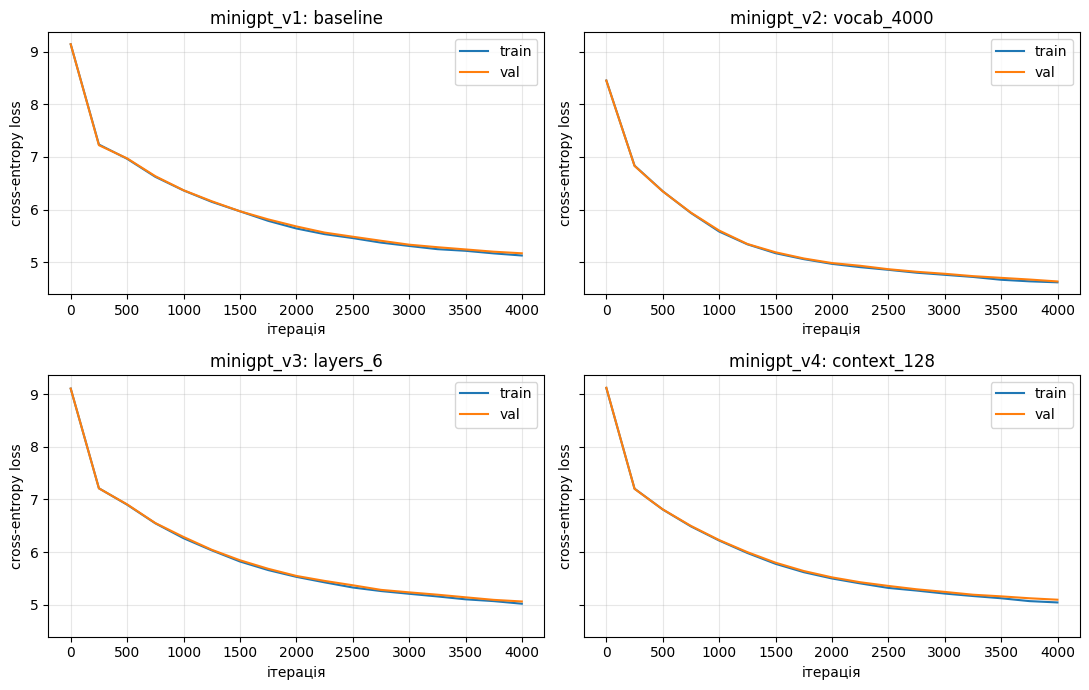

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
for ax, cfg in zip(axes.ravel(), VARIANTS):
    h = histories[cfg["name"]]
    ax.plot(h["iters"], h["train"], label="train")
    ax.plot(h["iters"], h["val"], label="val")
    ax.set_title(f'{cfg["name"]}: {cfg["desc"]}')
    ax.set_xlabel("ітерація")
    ax.set_ylabel("cross-entropy loss")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 3.3. Генерація на кращому за `val_loss` чекпоінті

In [17]:
PROMPT = "Президент України"
GEN_CHARS = 200

def generate_from_checkpoint(cfg, prompt, temperature=0.8, top_k=40):
    corpus = corpora[cfg["vocab_size"]]
    tok = corpus["tokenizer"]
    model = build_model(cfg)
    model.load_state_dict(torch.load(os.path.join(MODELS_DIR, f'{cfg["name"]}.pt'), map_location=device))
    prompt_ids = torch.tensor([tok.encode(prompt).ids], dtype=torch.long, device=device)
    n_new = round(GEN_CHARS / corpus["chars_per_token"])
    torch.manual_seed(SEED)
    out_ids = model.generate(prompt_ids, n_new, temperature=temperature, top_k=top_k)
    text = tok.decode(out_ids[0].tolist())
    del model, prompt_ids, out_ids
    release_gpu()
    return text

for cfg in VARIANTS:
    row = mini_gpt_df[mini_gpt_df["model"] == cfg["name"]].iloc[0]
    print(f"=== {cfg['name']} ({cfg['desc']}), best iter {row['best_iter']}, val_loss={row['val_loss']:.3f} ===")
    print(generate_from_checkpoint(cfg, PROMPT))
    print()

=== minigpt_v1 (baseline), best iter 3999, val_loss=5.169 ===
Президент України в Маго-К.За його словами, в місті Києва за останні місяці.Вперше, що він просто не будуть, а потім, що у нас під час.Відраховуючись в нас, у нас є більш-переми.

=== minigpt_v2 (vocab_4000), best iter 3999, val_loss=4.634 ===
Президент України в Магеданського.За словами, в якій в умовах не воно потрібно до того, адже невикійде, а потім на якому вже все підлітку.На моменті, хто під час в тю-пошенко.Також все це зробити старший, що

=== minigpt_v3 (layers_6), best iter 3999, val_loss=5.061 ===
Президент України в Магони.Бурні, що їхнялося й не було.Вважаю, що він вважає, що він зазначив, що її у столиці під час брифінгу буде незначу, що в яких не в Україні за добу.Якби ж

=== minigpt_v4 (context_128), best iter 3999, val_loss=5.094 ===
Президент України в Магайданського.За інформацією, в Одесі з’являться до 1 до цього року.І це не дуже добре, але що це вже все ще й не буде не зміг.У нас, не в Україні за добу 

In [18]:
base = mini_gpt_df.iloc[0]
best_loss = mini_gpt_df.loc[mini_gpt_df["val_loss"].idxmin()]
best_char = mini_gpt_df.loc[mini_gpt_df["val_loss_per_char"].idxmin()]

print(f"Найнижчий val_loss: {best_loss['model']} ({best_loss['variant']}) = {best_loss['val_loss']:.3f}")
print(
    f"Найнижчий val_loss на символ (чесне порівняння між різними словниками): "
    f"{best_char['model']} ({best_char['variant']}) = {best_char['val_loss_per_char']:.4f}"
)

effects = {}
for _, row in mini_gpt_df.iloc[1:].iterrows():
    delta = (row["val_loss_per_char"] - base["val_loss_per_char"]) / base["val_loss_per_char"]
    effects[row["variant"]] = delta
    direction = "краще" if delta < 0 else "гірше"
    print(f"{row['variant']:<14} відносно baseline: {delta:+.2%} ({direction})")

top_change = max(effects, key=lambda k: abs(effects[k]))
print(f"Найбільший ефект дала зміна «{top_change}» ({effects[top_change]:+.2%} до val_loss на символ).")

Найнижчий val_loss: minigpt_v2 (vocab_4000) = 4.634
Найнижчий val_loss на символ (чесне порівняння між різними словниками): minigpt_v3 (layers_6) = 1.4131
vocab_4000     відносно baseline: +4.02% (гірше)
layers_6       відносно baseline: -2.09% (краще)
context_128    відносно baseline: -1.44% (краще)
Найбільший ефект дала зміна «vocab_4000» (+4.02% до val_loss на символ).


In [19]:
import ctypes
import psutil

def ram_gb():
    return psutil.Process(os.getpid()).memory_info().rss / 1024 ** 3

print(f"RAM до очищення: {ram_gb():.2f} ГБ")

plt.close("all")

for name in [
    "ukr_dataset", "texts", "corpus_text", "word_counts", "sentence_lengths",
    "base_tokenizer", "warmup_tokenizer", "probe", "text_batches",
    "bpe_cmp", "wp_cmp", "uni_cmp", "comparison", "sample_texts", "sample_counts",
    "rows", "row", "encodings", "tokenizer_table", "shortest", "longest",
    "tok", "token_ids", "data", "corpora", "histories", "mini_gpt_df",
    "fig", "axes", "ax", "h", "cfg", "result", "history", "base", "best_loss", "best_char", "effects",
    "VARIANTS", "train_bpe", "encode_corpus", "build_model", "make_batch_fn", "estimate_loss",
    "train_variant", "generate_from_checkpoint",
    "AttentionHead", "MultiHeadAttention", "FeedForward", "TransformerBlock", "MiniGPT",
    "SummaryWriter",
]:
    globals().pop(name, None)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()
    print(f"GPU-пам'ять, зайнята тензорами: {torch.cuda.memory_allocated() / 1024 ** 3:.2f} ГБ")

try:
    ctypes.CDLL("libc.so.6").malloc_trim(0)
except OSError:
    pass

print(f"RAM після очищення: {ram_gb():.2f} ГБ")

RAM до очищення: 3.69 ГБ
GPU-пам'ять, зайнята тензорами: 0.02 ГБ
RAM після очищення: 3.12 ГБ


---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

### 4.0. Запустіть приклади виконання різних NLP задач

In [20]:
!pip install "transformers<5"

In [21]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f (https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Device set to use cuda:0


[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [22]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1 (https://huggingface.co/facebook/bart-large-mnli).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0


{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.844595193862915, 0.11197695881128311, 0.04342786595225334]}

In [23]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

No model was supplied, defaulted to openai-community/gpt2 and revision 607a30d (https://huggingface.co/openai-community/gpt2).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

...

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0
Truncation was not explicitly activated but `max_length` is provided a specific value, please use `truncation=True` to explicitly truncate examples to max length. Defaulting to 'longest_first' truncation strategy. If you encode pairs of sequences (GLUE-style) with the tokenizer you can select this strategy more precisely by providing a specific strategy to `truncation`.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': 'In this course, we will teach you how to play the game of the game. This course is based on an interview with a friend from the game (who was with the game) and we will give you some information on how to play the game of the game.\n\n\n\nWe will be going through the entire course in detail on how to play the game of the game. In short, the game can be played in 3 dimensions (1×2 x 2×1×2) and in a cube (1×2 x 1×2×2).\nWe will have a look at the actual cube (the cube that is about as big as the first cube).\nThere are 3 different cube types\nI will be giving you a quick overview of all 3 types of cubes.\n1. The cube that is about as big as the first cube. 2. The cube that is about as big as the first cube. 3. The cube that is about as big as the first cube.\nYou can see that the cube that is about as big as the first cube.\nThe cube that is about as big as the first cube.\nIn the end, the cube that is about as big as the first cube.\nThere are two types of cubes:\n1

In [24]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8 (https://huggingface.co/distilbert/distilroberta-base).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/331M [00:00<?, ?B/s]

Some weights of the model checkpoint at distilbert/distilroberta-base were not used when initializing RobertaForMaskedLM: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0


[{'score': 0.19619743525981903,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052695631980896,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [25]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496 (https://huggingface.co/dbmdz/bert-large-cased-finetuned-conll03-english).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

Some weights of the model checkpoint at dbmdz/bert-large-cased-finetuned-conll03-english were not used when initializing BertForTokenClassification: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing BertForTokenClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForTokenClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Device set to use cuda:0


[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [26]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("question-answering")
question_answerer(
    question="Where do I work?",
    context="My name is Sylvain and I work at Hugging Face in Brooklyn",
)

No model was supplied, defaulted to distilbert/distilbert-base-cased-distilled-squad and revision 564e9b5 (https://huggingface.co/distilbert/distilbert-base-cased-distilled-squad).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/473 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/261M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0


{'score': 0.6949763894081116, 'start': 33, 'end': 45, 'answer': 'Hugging Face'}

In [27]:
# Summarization
from transformers import pipeline

summarizer = pipeline("summarization")
summarizer(
    """
    America has changed dramatically during recent years. Not only has the number of
    graduates in traditional engineering disciplines such as mechanical, civil,
    electrical, chemical, and aeronautical engineering declined, but in most of
    the premier American universities engineering curricula now concentrate on
    and encourage largely the study of engineering science. As a result, there
    are declining offerings in engineering subjects dealing with infrastructure,
    the environment, and related issues, and greater concentration on high
    technology subjects, largely supporting increasingly complex scientific
    developments. While the latter is important, it should not be at the expense
    of more traditional engineering.

    Rapidly developing economies such as China and India, as well as other
    industrial countries in Europe and Asia, continue to encourage and advance
    the teaching of engineering. Both China and India, respectively, graduate
    six and eight times as many traditional engineers as does the United States.
    Other industrial countries at minimum maintain their output, while America
    suffers an increasingly serious decline in the number of engineering graduates
    and a lack of well-educated engineers.
"""
)

No model was supplied, defaulted to sshleifer/distilbart-cnn-12-6 and revision a4f8f3e (https://huggingface.co/sshleifer/distilbart-cnn-12-6).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

Device set to use cuda:0


[{'summary_text': ' The number of engineering graduates in the United States has declined in recent years . China and India graduate six and eight times as many traditional engineers as the U.S. does . Rapidly developing economies such as China continue to encourage and advance the teaching of engineering . There are declining offerings in engineering subjects dealing with infrastructure, infrastructure, the environment, and related issues .'}]

In [9]:
# Translation
from transformers import pipeline

translator = pipeline("translation", model="Helsinki-NLP/opus-mt-fr-en")
translator("Ce cours est produit par Hugging Face.")

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/301M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")
Device set to use cpu


[{'translation_text': 'This course is produced by Hugging Face.'}]

### 4.1. Свої приклади

Повторіть **усі 8 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, question-answering, summarization, translation), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

In [28]:
!pip install -q sentencepiece protobuf

In [29]:
from transformers import pipeline

PIPE_DEVICE = 0 if torch.cuda.is_available() else -1

def free_memory(*names):
    for name in names:
        globals().pop(name, None)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

In [30]:
sentiment_pipe = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
    device=PIPE_DEVICE,
)
print(sentiment_pipe("Я чекав на такий курс усе своє життя!"))
print(sentiment_pipe([
    "Сьогодні був чудовий день, я дуже радий!",
    "Цей сервіс працює жахливо, більше ним не користуватимусь.",
    "Завтра о десятій годині відбудеться лекція.",
]))
free_memory("sentiment_pipe")

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Device set to use cuda:0


[{'label': 'positive', 'score': 0.5548132061958313}]
[{'label': 'positive', 'score': 0.9296922087669373}, {'label': 'negative', 'score': 0.8741675615310669}, {'label': 'neutral', 'score': 0.7772568464279175}]


In [31]:
zero_shot_pipe = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
    device=PIPE_DEVICE,
)
print(zero_shot_pipe(
    "Верховна Рада ухвалила закон про електронне декларування доходів чиновників",
    candidate_labels=["політика", "спорт", "економіка", "освіта"],
    hypothesis_template="Цей текст про {}.",
))
free_memory("zero_shot_pipe")

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/558M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.3M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

Device set to use cuda:0


{'sequence': 'Верховна Рада ухвалила закон про електронне декларування доходів чиновників', 'labels': ['політика', 'освіта', 'спорт', 'економіка'], 'scores': [0.8896758556365967, 0.05580225586891174, 0.03148617222905159, 0.023035777732729912]}


In [32]:
generator_pipe = pipeline("text-generation", model="malteos/gpt2-uk", device=PIPE_DEVICE)
print(generator_pipe("У цьому курсі ми навчимо вас", max_new_tokens=40, do_sample=True))
print(generator_pipe(
    "Одного разу вночі студент прокинувся від дивного шуму",
    max_new_tokens=40,
    num_return_sequences=2,
    do_sample=True,
    temperature=0.8,
    top_k=50,
))
free_memory("generator_pipe")

config.json:   0%|          | 0.00/958 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/511M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/344 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/96.0 [00:00<?, ?B/s]

Device set to use cuda:0


[{'generated_text': "У цьому курсі ми навчимо вас основам управління проектами на комп'ютері.\n4. Програмне забезпечення\nПрограмне забезпечення (англ. програма) — це програмне забезпечення, призначена для підтримки роботи додатків і роботи програм на комп'ютері.\nПрограмне"}]
[{'generated_text': 'Одного разу вночі студент прокинувся від дивного шуму. Спускалось сонце по краях хмар, і він з усієї сили намагався зазирати до школи. Проте, як виявилося, нічого особливого, окрім жахливого шуму, не сталося. Та все ж'}, {'generated_text': 'Одного разу вночі студент прокинувся від дивного шуму, а коли він зненацька зупинився, то побачив, що його тіло зарилося, і почав повільно вилизувати з нього шкіру. Він почав здувати його, і він почав робити щось'}]


In [33]:
unmasker_pipe = pipeline("fill-mask", model="ukr-models/xlm-roberta-base-uk", device=PIPE_DEVICE)
print(unmasker_pipe("Київ — це <mask> України.", top_k=3))
free_memory("unmasker_pipe")

config.json:   0%|          | 0.00/711 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/460 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/854k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

Device set to use cuda:0


[{'score': 0.353222131729126, 'token': 7899, 'token_str': 'символ', 'sequence': 'Київ — це символ України.'}, {'score': 0.17146968841552734, 'token': 5317, 'token_str': 'центр', 'sequence': 'Київ — це центр України.'}, {'score': 0.12493699789047241, 'token': 26935, 'token_str': 'столиці', 'sequence': 'Київ — це столиці України.'}]


In [34]:
ner_pipe = pipeline("ner", model="ukr-models/uk-ner", aggregation_strategy="simple", device=PIPE_DEVICE)
print(ner_pipe("Мене звати Олена, я працюю в компанії «Нова пошта» у Львові."))
free_memory("ner_pipe")

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/854k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

Device set to use cuda:0
Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


[{'entity_group': 'PER', 'score': np.float32(0.9999753), 'word': 'О', 'start': 10, 'end': 12}, {'entity_group': 'PER', 'score': np.float32(0.9999653), 'word': 'лена', 'start': 12, 'end': 16}, {'entity_group': 'ORG', 'score': np.float32(0.9998306), 'word': 'Нова пошта', 'start': 39, 'end': 49}, {'entity_group': 'LOC', 'score': np.float32(0.99998546), 'word': 'Львові', 'start': 52, 'end': 59}]


In [35]:
qa_pipe = pipeline("question-answering", model="deepset/xlm-roberta-base-squad2", device=PIPE_DEVICE)
print(qa_pipe(
    question="Де я працюю?",
    context="Мене звати Олена, і я працюю в компанії «Нова пошта» у Львові.",
))
free_memory("qa_pipe")

config.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/79.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Device set to use cuda:0


{'score': 0.5761243500746787, 'start': 39, 'end': 52, 'answer': ' «Нова пошта»'}


In [36]:
summarizer_pipe = pipeline("summarization", model="csebuetnlp/mT5_multilingual_XLSum", device=PIPE_DEVICE)

summary_source = " ".join("""
Українські університети дедалі активніше впроваджують штучний інтелект у навчальний процес.
Студенти використовують мовні моделі для пошуку джерел, перевірки коду та підготовки до іспитів,
а викладачі шукають способи оцінювати знання так, щоб відповіді нейромережі не підміняли власні міркування.
У багатьох закладах уже з'явилися правила академічної доброчесності, які дозволяють користуватися
такими інструментами лише з обов'язковим зазначенням того, як саме вони були застосовані.
Експерти зауважують, що головна мета полягає не в заборонах, а у вихованні критичного ставлення
до згенерованих відповідей, адже моделі можуть помилятися і впевнено стверджувати неправдиві речі.
""".split())

print(summarizer_pipe(summary_source, max_length=64, min_length=16, num_beams=4, no_repeat_ngram_size=2))
free_memory("summarizer_pipe", "summary_source")

config.json:   0%|          | 0.00/730 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/2.33G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.33G [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565
/usr/local/lib/python3.13/dist-packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(
Device set to use cuda:0


[{'summary_text': "В Україні з'явилися нові правила, які дозволять студентам користуватися штучним інтелектом."}]


In [37]:
translator_pipe = pipeline("translation", model="Helsinki-NLP/opus-mt-uk-en", device=PIPE_DEVICE)
print(translator_pipe("Цей курс підготовлено в Житомирській політехніці."))
free_memory("translator_pipe")

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/305M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/305M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/1.01M [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/809k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")
Device set to use cuda:0


[{'translation_text': 'This course was prepared at the Zhytomyric police station.'}]


### 4.2. Механіка `pipeline()`

Вправи для розуміння механіки (за [HF LLM Course, Chapter 2](https://huggingface.co/learn/llm-course/en/chapter2/1)):
- Розберіть `pipeline()` "зсередини" — токенізатор → модель → post-processing — своїми словами, спираючись на §2.2-2.4 курсу.
- Покажіть, що відбувається з `padding`/`truncation`/`attention_mask`, коли в один батч потрапляють речення різної довжини (§2.5-2.6 курсу) — на своїх прикладах.

In [38]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MECH_MODEL = "lxyuan/distilbert-base-multilingual-cased-sentiments-student"
mech_tokenizer = AutoTokenizer.from_pretrained(MECH_MODEL)
mech_model = AutoModelForSequenceClassification.from_pretrained(MECH_MODEL).eval()

sentence = "Цей курс просто чудовий!"
inputs = mech_tokenizer(sentence, return_tensors="pt")
print(inputs)
print(mech_tokenizer.convert_ids_to_tokens(inputs["input_ids"][0]))

with torch.no_grad():
    outputs = mech_model(**inputs)

print("Логіти:", outputs.logits)
probs = F.softmax(outputs.logits, dim=-1)[0]
for idx, p in enumerate(probs):
    print(f"{mech_model.config.id2label[idx]:<10} {p.item():.4f}")

tokenizer_config.json:   0%|          | 0.00/373 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/541M [00:00<?, ?B/s]

{'input_ids': tensor([[  101, 36759, 41885, 31108, 59172, 66809, 10384,   106,   102]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1]])}
['[CLS]', 'Цей', 'курс', 'просто', 'чу', '##дови', '##й', '!', '[SEP]']
Логіти: tensor([[-0.1955, -0.7775,  1.1333]])
positive   0.1874
neutral    0.1047
negative   0.7079


In [39]:
batch_sentences = [
    "Класно!",
    "Сьогодні я цілий день ходив по місту, зустрічався з друзями, багато сміявся і повернувся додому щасливим.",
    "Ні.",
]

batch = mech_tokenizer(batch_sentences, padding=True, truncation=True, max_length=16, return_tensors="pt")
print("Форма input_ids:", tuple(batch["input_ids"].shape))
print("input_ids:\n", batch["input_ids"])
print("attention_mask:\n", batch["attention_mask"])
for ids in batch["input_ids"]:
    print(mech_tokenizer.convert_ids_to_tokens(ids))

full = mech_tokenizer(batch_sentences[1], return_tensors="pt")
print("\nДовжина довгого речення без truncation:", full["input_ids"].shape[1], "токенів")
print("Довжина в батчі з max_length=16:", batch["input_ids"].shape[1], "токенів")

Форма input_ids: (3, 16)
input_ids:
 tensor([[   101,    519,  38445,  10636,    106,    102,      0,      0,      0,
              0,      0,      0,      0,      0,      0,      0],
        [   101,    526,  81383,  44199,    572,  24899,  27311,  16276, 105569,
          17971,  10297,  56752,  10227,    117,    548,    102],
        [   101,    522,  10352,    119,    102,      0,      0,      0,      0,
              0,      0,      0,      0,      0,      0,      0]])
attention_mask:
 tensor([[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])
['[CLS]', 'К', '##лас', '##но', '!', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
['[CLS]', 'С', '##ього', '##дні', 'я', 'ці', '##лий', 'день', 'ход', '##ив', 'по', 'міст', '##у', ',', 'з', '[SEP]']
['[CLS]', 'Н', '##і', '.', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PA

In [40]:
with torch.no_grad():
    logits_batch = mech_model(**batch).logits
    logits_no_mask = mech_model(input_ids=batch["input_ids"]).logits
    logits_single = torch.cat([
        mech_model(**mech_tokenizer(s, truncation=True, max_length=16, return_tensors="pt")).logits
        for s in batch_sentences
    ])

print("Макс. різниця «батч з маскою» vs «по одному»:", (logits_batch - logits_single).abs().max().item())
print("Макс. різниця «батч без маски» vs «по одному»:", (logits_no_mask - logits_single).abs().max().item())

We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.


Макс. різниця «батч з маскою» vs «по одному»: 4.76837158203125e-07
Макс. різниця «батч без маски» vs «по одному»: 0.6536240577697754


In [41]:
del mech_tokenizer, mech_model, inputs, outputs, batch, full, logits_batch, logits_no_mask, logits_single
free_memory()

---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |
| question-answering | F1 / Exact Match | кілька `(context, question, правильна_відповідь)` | [`squad`](https://huggingface.co/spaces/evaluate-metric/squad) |
| summarization | ROUGE-1/2/L | текст + "еталонна" сумаризація (можете написати самі) | [`rouge`](https://huggingface.co/spaces/evaluate-metric/rouge) |
| translation | BLEU | текст + один-два еталонні переклади | [`sacrebleu`](https://huggingface.co/spaces/evaluate-metric/sacrebleu) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу (як KV-кеш вимірювали в 5 демо) та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, `max_length`/beam search для сумаризації й перекладу, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

In [42]:
!pip install -q evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.5 MB/s eta 0:00:00


In [43]:
import evaluate

accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

labeled_sentences = [
    ("Дякую за швидку доставку, усе прийшло в ідеальному стані!", 1),
    ("Лекція була неймовірно цікавою, я дізнався купу нового.", 1),
    ("Це найсмачніша піца, яку я куштував за останні роки.", 1),
    ("Команда підтримки допомогла вирішити проблему за п'ять хвилин, просто чудово.", 1),
    ("Сьогодні чудова погода, і настрій просто відмінний.", 1),
    ("Фільм вразив мене до глибини душі, раджу всім переглянути.", 1),
    ("Новий телефон працює швидко, а камера робить приголомшливі знімки.", 1),
    ("Я дуже радий, що вдалося скласти іспит з першої спроби.", 1),
    ("Готель виявився затишним, персонал привітний, повернуся сюди ще.", 1),
    ("Прогулянка Карпатами подарувала мені незабутні враження.", 1),
    ("Замовлення спізнилося на тиждень, а менеджер навіть не вибачився.", 0),
    ("Ця лекція була нудною, я ледве дочекався її кінця.", 0),
    ("Їжа була холодною та несмачною, більше сюди не прийду.", 0),
    ("Додаток постійно вилітає, користуватися ним неможливо.", 0),
    ("Весь день ллє дощ, і настрій просто жахливий.", 0),
    ("Сюжет передбачуваний, а акторська гра відверто слабка.", 0),
    ("Телефон перегрівається й розряджається за кілька годин.", 0),
    ("Я дуже засмутився, коли дізнався, що поїздку скасували.", 0),
    ("У номері було брудно, а персонал поводився грубо.", 0),
    ("Черга в поліклініці тривала три години, це просто знущання.", 0),
]
eval_texts = [t for t, _ in labeled_sentences]
eval_labels = [l for _, l in labeled_sentences]

POSITIVE_LABELS = {"positive", "pos", "label_2", "4 stars", "5 stars"}
NEGATIVE_LABELS = {"negative", "neg", "label_0", "1 star", "2 stars"}

def positive_share(all_scores):
    pos = sum(s["score"] for s in all_scores if s["label"].lower() in POSITIVE_LABELS)
    neg = sum(s["score"] for s in all_scores if s["label"].lower() in NEGATIVE_LABELS)
    return pos / (pos + neg)

def predict_positive_share(pipe, batch_texts, max_length=128):
    outputs = pipe(batch_texts, top_k=None, truncation=True, max_length=max_length, batch_size=8)
    return [positive_share(o) for o in outputs]

def score_predictions(shares, threshold=0.5):
    preds = [int(s >= threshold) for s in shares]
    return {
        "accuracy": accuracy_metric.compute(predictions=preds, references=eval_labels)["accuracy"],
        "f1": f1_metric.compute(predictions=preds, references=eval_labels)["f1"],
    }

## 5.2. Порівняння моделей

In [44]:
SENTIMENT_MODELS = {
    "xlmr_twitter": "cardiffnlp/twitter-xlm-roberta-base-sentiment",
    "distilbert_multi": "lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    "bert_nlptown": "nlptown/bert-base-multilingual-uncased-sentiment",
}

comparison_rows = []
for key, model_id in SENTIMENT_MODELS.items():
    pipe = pipeline("sentiment-analysis", model=model_id, device=PIPE_DEVICE)
    n_params = sum(p.numel() for p in pipe.model.parameters())
    predict_positive_share(pipe, eval_texts[:2])
    start = time.perf_counter()
    shares = predict_positive_share(pipe, eval_texts)
    elapsed = time.perf_counter() - start
    metrics = score_predictions(shares)
    comparison_rows.append({
        "experiment": "sentiment-analysis",
        "model": key,
        "variant": "default",
        "model_id": model_id,
        "params": n_params,
        "accuracy": metrics["accuracy"],
        "f1": metrics["f1"],
        "inference_seconds_20_texts": elapsed,
    })
    del pipe
    free_memory()

model_comparison_df = pd.DataFrame(comparison_rows)
display(model_comparison_df)
results_rows.extend(comparison_rows)

Device set to use cuda:0
Device set to use cuda:0


config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/669M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Device set to use cuda:0


,experiment,model,variant,model_id,params,accuracy,f1,inference_seconds_20_texts
0,sentiment-analysis,xlmr_twitter,default,cardiffnlp/twitter-xlm-roberta-base-sentiment,278045955,1.00,1.000000,0.116889
1,sentiment-analysis,distilbert_multi,default,lxyuan/distilbert-base-multilingual-cased-sent...,135326979,0.65,0.533333,0.056203
2,sentiment-analysis,bert_nlptown,default,nlptown/bert-base-multilingual-uncased-sentiment,167360261,0.90,0.888889,0.092481


## 5.3. Налаштування кращої моделі

In [45]:
best_key = max(comparison_rows, key=lambda r: (r["f1"], r["accuracy"]))["model"]
best_pipe = pipeline("sentiment-analysis", model=SENTIMENT_MODELS[best_key], device=PIPE_DEVICE)

experiments = [
    ("baseline", {"threshold": 0.5, "max_length": 128, "lowercase": False}),
    ("threshold=0.3", {"threshold": 0.3, "max_length": 128, "lowercase": False}),
    ("threshold=0.7", {"threshold": 0.7, "max_length": 128, "lowercase": False}),
    ("max_length=6", {"threshold": 0.5, "max_length": 6, "lowercase": False}),
    ("lowercase_input", {"threshold": 0.5, "max_length": 128, "lowercase": True}),
]

tuning_rows = []
for label, options in experiments:
    batch_texts = [t.lower() for t in eval_texts] if options["lowercase"] else eval_texts
    shares = predict_positive_share(best_pipe, batch_texts, max_length=options["max_length"])
    metrics = score_predictions(shares, threshold=options["threshold"])
    tuning_rows.append({
        "experiment": "sentiment-tuning",
        "model": best_key,
        "variant": label,
        "model_id": SENTIMENT_MODELS[best_key],
        "accuracy": metrics["accuracy"],
        "f1": metrics["f1"],
    })

tuning_df = pd.DataFrame(tuning_rows)
display(tuning_df)
results_rows.extend(tuning_rows)

del best_pipe
free_memory()

Device set to use cuda:0


,experiment,model,variant,model_id,accuracy,f1
0,sentiment-tuning,xlmr_twitter,baseline,cardiffnlp/twitter-xlm-roberta-base-sentiment,1.0,1.000000
1,sentiment-tuning,xlmr_twitter,threshold=0.3,cardiffnlp/twitter-xlm-roberta-base-sentiment,1.0,1.000000
2,sentiment-tuning,xlmr_twitter,threshold=0.7,cardiffnlp/twitter-xlm-roberta-base-sentiment,1.0,1.000000
3,sentiment-tuning,xlmr_twitter,max_length=6,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.6,0.636364
4,sentiment-tuning,xlmr_twitter,lowercase_input,cardiffnlp/twitter-xlm-roberta-base-sentiment,1.0,1.000000


In [46]:
best_setting = tuning_df.loc[tuning_df["f1"].idxmax()]
settings_spread = tuning_df["f1"].max() - tuning_df["f1"].min()
models_spread = model_comparison_df["f1"].max() - model_comparison_df["f1"].min()

print(f"Найкраща модель за F1 без налаштувань: {best_key}")
print(f"Найкраща комбінація: {best_key} + {best_setting['variant']} (accuracy={best_setting['accuracy']:.2f}, f1={best_setting['f1']:.2f})")
print(f"Розкид F1 між моделями: {models_spread:.3f}")
print(f"Розкид F1 між налаштуваннями однієї моделі: {settings_spread:.3f}")
print("Вибір моделі вплинув сильніше." if models_spread > settings_spread else "Налаштування вплинули не менше, ніж вибір моделі.")

results_df = pd.DataFrame(results_rows)
results_df.to_csv(os.path.join(LAB_DIR, "results.csv"), index=False)
display(results_df)

Найкраща модель за F1 без налаштувань: xlmr_twitter
Найкраща комбінація: xlmr_twitter + baseline (accuracy=1.00, f1=1.00)
Розкид F1 між моделями: 0.467
Розкид F1 між налаштуваннями однієї моделі: 0.364
Вибір моделі вплинув сильніше.


,experiment,model,variant,vocab_size,context_len,n_layers,n_heads,max_iters,params,best_iter,val_loss,val_loss_per_char,train_minutes,model_id,accuracy,f1,inference_seconds_20_texts
0,mini-GPT,minigpt_v1,baseline,8000.0,64.0,4.0,4.0,4000.0,2856000.0,3999.0,5.168683,1.443199,2.444906,NaN,NaN,NaN,NaN
1,mini-GPT,minigpt_v2,vocab_4000,4000.0,64.0,4.0,4.0,4000.0,1828000.0,3999.0,4.633839,1.501245,2.143217,NaN,NaN,NaN,NaN
2,mini-GPT,minigpt_v3,layers_6,8000.0,64.0,6.0,4.0,4000.0,3251776.0,3999.0,5.060756,1.413063,3.341024,NaN,NaN,NaN,NaN
3,mini-GPT,minigpt_v4,context_128,8000.0,128.0,4.0,4.0,4000.0,2864192.0,3999.0,5.094286,1.422425,4.787897,NaN,NaN,NaN,NaN
4,sentiment-analysis,xlmr_twitter,default,NaN,NaN,NaN,NaN,NaN,278045955.0,NaN,NaN,NaN,NaN,cardiffnlp/twitter-xlm-roberta-base-sentiment,1.00,1.000000,0.116889
5,sentiment-analysis,distilbert_multi,default,NaN,NaN,NaN,NaN,NaN,135326979.0,NaN,NaN,NaN,NaN,lxyuan/distilbert-base-multilingual-cased-sent...,0.65,0.533333,0.056203
6,sentiment-analysis,bert_nlptown,default,NaN,NaN,NaN,NaN,NaN,167360261.0,NaN,NaN,NaN,NaN,nlptown/bert-base-multilingual-uncased-sentiment,0.90,0.888889,0.092481
7,sentiment-tuning,xlmr_twitter,baseline,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,cardiffnlp/twitter-xlm-roberta-base-sentiment,1.00,1.000000,NaN
8,sentiment-tuning,xlmr_twitter,threshold=0.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,cardiffnlp/twitter-xlm-roberta-base-sentiment,1.00,1.000000,NaN
9,sentiment-tuning,xlmr_twitter,threshold=0.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,cardiffnlp/twitter-xlm-roberta-base-sentiment,1.00,1.000000,NaN


---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

In [51]:
!pip install -q "transformers<5" "huggingface_hub>=0.34,<1.0" gradio

In [1]:
import torch
import gradio as gr
from transformers import pipeline

PIPE_DEVICE = 0 if torch.cuda.is_available() else -1

news_sentiment = pipeline(
    "sentiment-analysis",
    model="lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    device=PIPE_DEVICE,
)
news_topic = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
    device=PIPE_DEVICE,
)
news_ner = pipeline("ner", model="ukr-models/uk-ner", aggregation_strategy="simple", device=PIPE_DEVICE)
news_translator = pipeline("translation", model="Helsinki-NLP/opus-mt-uk-en", device=PIPE_DEVICE)

TOPICS = ["політика", "економіка", "війна і безпека", "спорт", "культура", "суспільство", "наука і технології"]

def to_highlight(text, entities):
    spans = []
    cursor = 0
    for ent in sorted(entities, key=lambda e: e["start"]):
        if ent["start"] > cursor:
            spans.append((text[cursor:ent["start"]], None))
        spans.append((text[ent["start"]:ent["end"]], ent["entity_group"]))
        cursor = ent["end"]
    if cursor < len(text):
        spans.append((text[cursor:], None))
    return spans

def news_xray(text):
    text = (text or "").strip()
    if not text:
        return {}, {}, [], ""
    tone = {s["label"]: s["score"] for s in news_sentiment(text, top_k=None)}
    topic_result = news_topic(text, candidate_labels=TOPICS, hypothesis_template="Цей текст про {}.")
    topics = dict(zip(topic_result["labels"], topic_result["scores"]))
    highlighted = to_highlight(text, news_ner(text))
    translation = news_translator(text, max_length=256)[0]["translation_text"]
    return tone, topics, highlighted, translation

demo = gr.Interface(
    fn=news_xray,
    inputs=gr.Textbox(lines=4, label="Українське речення з новини"),
    outputs=[
        gr.Label(label="Тон"),
        gr.Label(label="Тема", num_top_classes=4),
        gr.HighlightedText(label="Іменовані сутності (PER / LOC / ORG)"),
        gr.Textbox(label="Переклад англійською"),
    ],
    title="Новинний рентген",
    description="Вставте речення з української новини: застосунок покаже емоційний тон, тему, імена, місця й організації та дасть англійський переклад.",
    examples=[
        ["Президент України Володимир Зеленський зустрівся у Києві з прем'єр-міністром Польщі та обговорив допомогу для Харкова."],
        ["Львівські волонтери зібрали рекордну суму на дрони, і це неймовірно надихає всіх нас!"],
        ["Нацбанк України попередив про зростання інфляції, а «Укрзалізниця» скасувала кілька рейсів до Житомира."],
    ],
)

demo.launch(share=True)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
Device set to use cuda:0
Device set to use cuda:0
Device set to use cuda:0
/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")
Device set to use cuda:0


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://675cf9c16cf3c4bb2e.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У форму (та сама, що й для попередніх лаб) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```